# 03 · Modelagem

Fase 4 do CRISP-DM. Compara quatro classificadores por etapa com validação cruzada agrupada por município (`StratifiedGroupKFold`, 5 dobras): referência aleatória (Dummy), Regressão Logística, Random Forest e Hist Gradient Boosting. Imputação, padronização e one-hot ficam dentro do pipeline, ajustados só no treino de cada dobra.

Cenários de sensibilidade: completo (com TDI), sem TDI (a TDI acumula atrasos passados) e sem horas-aula (par colinear com tempo integral).

Variáveis excluídas: aprovação, reprovação e Ideb (vazamento do alvo), `alvo_alto_abandono` (é o próprio rótulo), `tnr` e `matriculas` (substituída por `log_matriculas`), códigos de escola e município.

In [1]:
import os

REPO = "datasync-Projeto-CRISP-DM-abandono"
if not os.path.exists(REPO) and os.path.basename(os.getcwd()) != REPO:
    !git clone -q https://github.com/LuisGomes25/{REPO}.git
if os.path.basename(os.getcwd()) != REPO:
    os.chdir(REPO)

SAIDA = "resultados/03_modelagem"
os.makedirs(SAIDA, exist_ok=True)
print("Pasta de trabalho:", os.getcwd())

Pasta de trabalho: /content/datasync-Projeto-CRISP-DM-abandono


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
ETAPAS = ["ensino_medio", "anos_finais", "anos_iniciais"]
NUM_BASE = ["atu_alunos_turma", "had_horas_aula", "dsu_doc_superior", "afd_formacao_adequada",
            "ied_esforco_alto", "icg_complexidade", "ird_regularidade", "inse_media",
            "flag_inse_ausente", "log_matriculas", "pct_noturno", "pct_integral",
            "pct_transporte_publico", "alunos_por_docente", "indice_infra", "flag_sem_turma_etapa"]
CAT_BASE = ["SG_UF", "NO_CATEGORIA", "NO_DEPENDENCIA"]
CENARIOS = {
    "completo_com_tdi": ["tdi_distorcao"] + NUM_BASE,
    "sem_tdi": NUM_BASE,
    "sem_horas_aula": ["tdi_distorcao"] + [c for c in NUM_BASE if c != "had_horas_aula"],
}

df = pd.read_csv("dados/tabela_analitica.csv", encoding="utf-8-sig",
                 dtype={"codigo_escola": str, "CO_MUNICIPIO": str}, low_memory=False)
assert df.shape == (136713, 27), df.shape

def criar_alvo(serie, percentil=80):
    limite = float(serie.quantile(percentil / 100))
    if limite == 0.0:
        return (serie > 0).astype(int), limite, "taxa > 0 (P80 = 0)"
    return (serie >= limite).astype(int), limite, f"taxa >= P80 ({limite:.2f}%)"

In [3]:
def montar_modelos(cols_num):
    prep = ColumnTransformer([
        ("num", Pipeline([("imputacao", SimpleImputer(strategy="median")),
                          ("escala", StandardScaler())]), cols_num),
        ("cat", Pipeline([("imputacao", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT_BASE),
    ])
    return {
        "Dummy": DummyClassifier(strategy="stratified", random_state=SEED),
        "Regressao_Logistica": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED),
        "Random_Forest": RandomForestClassifier(n_estimators=250, max_depth=14, min_samples_leaf=8,
                                                class_weight="balanced", random_state=SEED, n_jobs=-1),
        "Hist_Gradient_Boosting": HistGradientBoostingClassifier(max_iter=250, max_depth=6, learning_rate=0.05,
                                                                 min_samples_leaf=20, class_weight="balanced",
                                                                 random_state=SEED),
    }, prep

def avaliar(sub, y, cols_num):
    """Validação cruzada agrupada por município; devolve métricas e probabilidades fora da dobra."""
    X = sub[cols_num + CAT_BASE]
    grupos = sub["CO_MUNICIPIO"].values
    modelos, prep = montar_modelos(cols_num)
    linhas, oof = [], {}
    for nome, clf in modelos.items():
        prob = np.zeros(len(sub))
        for treino, teste in StratifiedGroupKFold(n_splits=5).split(X, y, grupos):
            pipe = Pipeline([("prep", prep), ("clf", clf)]).fit(X.iloc[treino], y[treino])
            prob[teste] = pipe.predict_proba(X.iloc[teste])[:, 1]
        pred = (prob >= 0.5).astype(int)
        linhas.append({"modelo": nome, "pr_auc": average_precision_score(y, prob),
                       "roc_auc": roc_auc_score(y, prob), "acuracia": accuracy_score(y, pred),
                       "acuracia_balanceada": balanced_accuracy_score(y, pred), "f1": f1_score(y, pred),
                       "recall": recall_score(y, pred), "precisao": precision_score(y, pred, zero_division=0)})
        oof[nome] = prob
    return pd.DataFrame(linhas), oof

In [4]:
resultados, alvos, matrizes = [], [], []
for etapa in ETAPAS:
    sub = df[df["etapa"] == etapa].dropna(subset=["taxa_abandono", "CO_MUNICIPIO"]).reset_index(drop=True)
    alvo, limite, regra = criar_alvo(sub["taxa_abandono"])
    y = alvo.values
    alvos.append({"etapa": etapa, "escolas": len(sub), "regra": regra,
                  "limite": limite, "pct_alto": round(y.mean() * 100, 2)})

    for cenario, cols_num in CENARIOS.items():
        tabela, oof = avaliar(sub, y, cols_num)
        tabela.insert(0, "cenario", cenario)
        tabela.insert(0, "etapa", etapa)
        tabela.insert(2, "prevalencia", y.mean())
        resultados.append(tabela)
        if cenario == "completo_com_tdi":
            melhor = tabela.sort_values("pr_auc", ascending=False).iloc[0]["modelo"]
            tn, fp, fn, tp = confusion_matrix(y, (oof[melhor] >= 0.5).astype(int)).ravel()
            matrizes.append({"etapa": etapa, "melhor_modelo": melhor, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
        print(f"{etapa:14s} {cenario:18s} ok", flush=True)

alvos = pd.DataFrame(alvos)
comparacao = pd.concat(resultados, ignore_index=True).round(4)
matrizes = pd.DataFrame(matrizes)
alvos.to_csv(os.path.join(SAIDA, "01_definicao_alvos.csv"), index=False, encoding="utf-8-sig")
comparacao.to_csv(os.path.join(SAIDA, "02_comparacao_modelos.csv"), index=False, encoding="utf-8-sig")
matrizes.to_csv(os.path.join(SAIDA, "03_matriz_confusao_melhores.csv"), index=False, encoding="utf-8-sig")
display(alvos, comparacao[comparacao["cenario"] == "completo_com_tdi"], matrizes)

ensino_medio   completo_com_tdi   ok
ensino_medio   sem_tdi            ok
ensino_medio   sem_horas_aula     ok
anos_finais    completo_com_tdi   ok
anos_finais    sem_tdi            ok
anos_finais    sem_horas_aula     ok
anos_iniciais  completo_com_tdi   ok
anos_iniciais  sem_tdi            ok
anos_iniciais  sem_horas_aula     ok


,etapa,escolas,regra,limite,pct_alto
0,ensino_medio,21229,taxa >= P80 (4.40%),4.4,20.03
1,anos_finais,44803,taxa >= P80 (1.80%),1.8,20.12
2,anos_iniciais,70681,taxa > 0 (P80 = 0),0.0,15.28


,etapa,cenario,prevalencia,modelo,pr_auc,roc_auc,acuracia,acuracia_balanceada,f1,recall,precisao
0,ensino_medio,completo_com_tdi,0.2003,Dummy,0.2003,0.4999,0.6802,0.4999,0.1997,0.1992,0.2001
1,ensino_medio,completo_com_tdi,0.2003,Regressao_Logistica,0.4937,0.8212,0.7212,0.7478,0.5324,0.7923,0.4008
2,ensino_medio,completo_com_tdi,0.2003,Random_Forest,0.5172,0.8265,0.7767,0.7431,0.5521,0.6872,0.4614
3,ensino_medio,completo_com_tdi,0.2003,Hist_Gradient_Boosting,0.5093,0.8280,0.7360,0.7489,0.5390,0.7705,0.4145
12,anos_finais,completo_com_tdi,0.2012,Dummy,0.2029,0.5050,0.6836,0.5050,0.2078,0.2062,0.2093
13,anos_finais,completo_com_tdi,0.2012,Regressao_Logistica,0.4720,0.8043,0.7325,0.7341,0.5257,0.7369,0.4086
14,anos_finais,completo_com_tdi,0.2012,Random_Forest,0.5039,0.8139,0.7647,0.7380,0.5424,0.6933,0.4455
15,anos_finais,completo_com_tdi,0.2012,Hist_Gradient_Boosting,0.5159,0.8210,0.7389,0.7469,0.5395,0.7604,0.4181
24,anos_iniciais,completo_com_tdi,0.1528,Dummy,0.1532,0.5013,0.7426,0.5013,0.1543,0.1537,0.1550
25,anos_iniciais,completo_com_tdi,0.1528,Regressao_Logistica,0.4125,0.8028,0.7196,0.7301,0.4482,0.7452,0.3205


,etapa,melhor_modelo,TN,FP,FN,TP
0,ensino_medio,Random_Forest,13566,3411,1330,2922
1,anos_finais,Hist_Gradient_Boosting,26250,9539,2160,6854
2,anos_iniciais,Hist_Gradient_Boosting,44428,15452,2910,7891


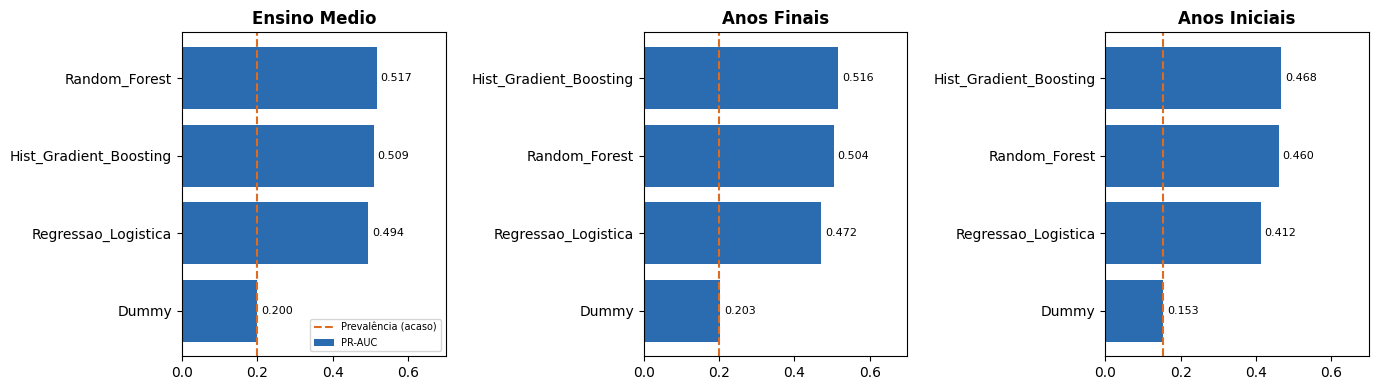

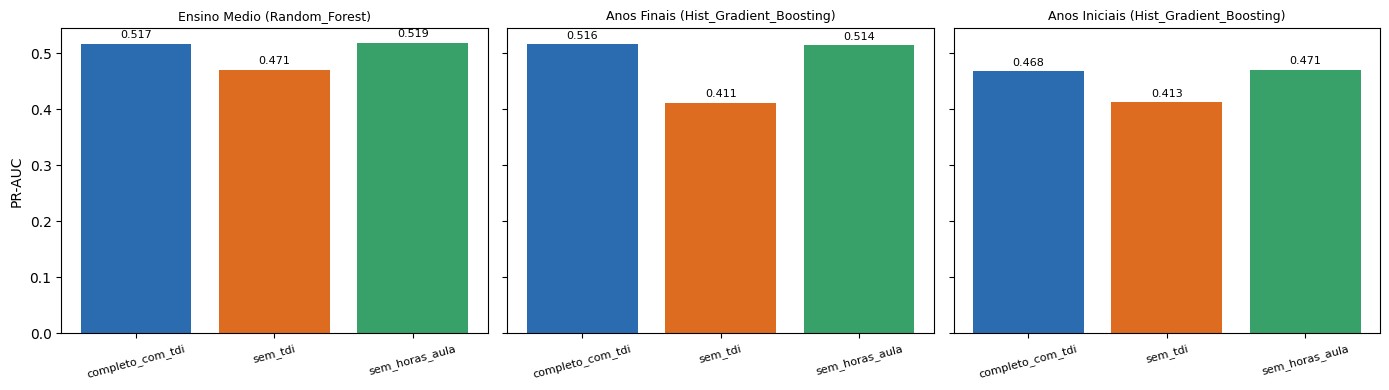

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
for i, etapa in enumerate(ETAPAS):
    d = comparacao[(comparacao["etapa"] == etapa) & (comparacao["cenario"] == "completo_com_tdi")]
    d = d.sort_values("pr_auc")
    eixos[i].barh(d["modelo"], d["pr_auc"], color="#2b6cb0", label="PR-AUC")
    eixos[i].axvline(d["prevalencia"].iloc[0], color="#dd6b20", linestyle="--", label="Prevalência (acaso)")
    for j, v in enumerate(d["pr_auc"]):
        eixos[i].text(v + 0.01, j, f"{v:.3f}", va="center", fontsize=8)
    eixos[i].set_xlim(0, 0.7)
    eixos[i].set_title(etapa.replace("_", " ").title(), fontweight="bold")
eixos[0].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(SAIDA, "01_comparacao_modelos.png"), dpi=300, bbox_inches="tight")
plt.show()

melhores = dict(zip(matrizes["etapa"], matrizes["melhor_modelo"]))
sens = comparacao[[melhores[e] == m for e, m in zip(comparacao["etapa"], comparacao["modelo"])]]
fig, eixos = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for i, etapa in enumerate(ETAPAS):
    d = sens[sens["etapa"] == etapa]
    eixos[i].bar(d["cenario"], d["pr_auc"], color=["#2b6cb0", "#dd6b20", "#38a169"])
    for j, v in enumerate(d["pr_auc"]):
        eixos[i].text(j, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    eixos[i].set_title(f"{etapa.replace('_', ' ').title()} ({melhores[etapa]})", fontsize=9)
    eixos[i].tick_params(axis="x", rotation=15, labelsize=8)
eixos[0].set_ylabel("PR-AUC")
plt.tight_layout()
plt.savefig(os.path.join(SAIDA, "02_sensibilidade_cenarios.png"), dpi=300, bbox_inches="tight")
plt.show()

In [6]:
!zip -qr /content/03_modelagem.zip resultados/03_modelagem
from google.colab import files
files.download("/content/03_modelagem.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>